# Phase Stretch Transform on the GPU (CuPy), Checked Against PhyCV

**Colin Casey, 2026.** Library: `dgs/pst_cuda.py` (tests: `tests/test_pst_cuda.py`). Reference: the installed `phycv` package (Jalali Lab, UCLA) [1], [2].

## In plain words

The **Phase Stretch Transform (PST)** finds edges. It takes the 2-D Fourier transform of an image, gives each spatial frequency a phase delay that grows with frequency, transforms back, and reads the **phase** of the result. Cracks and boundaries are made of high spatial frequencies, so they pick up the most phase and light up.

That is the same move as this repo's dispersion operator $H(\nu)=e^{i\pi D\nu^2}$: FFT, multiply by a phase, inverse FFT. Time-stretch phase retrieval uses it to *recover* a hidden phase; PST uses it to *inject* a phase and read edges out. A GPU does FFTs and per-pixel multiplies very fast, so PST is a natural CUDA job.

This notebook:

1. checks what PhyCV already ships for GPUs (it has a PyTorch `PST_GPU`, so this is not the first GPU PST);
2. derives the PST kernel and a small exact trick that cuts the FFT count per frame from 4 to 2;
3. runs `dgs.pst_cuda` (CuPy) on synthetic concrete-crack images and compares it pixel by pixel with `phycv.PST`;
4. times phycv CPU, phycv `PST_GPU`, and `dgs.pst_cuda` from 256² to 4096² pixels and fits *time = overhead + slope × pixels* by least squares (the `regress_line` method from `dgs/rigid_body_harsh.py`), reporting ns per pixel.

All numbers below are measured on this machine (RTX 4060 laptop GPU, CUDA 13, CuPy 13.6) when the notebook runs. Kernel: **py312**.

In [1]:
import sys, pathlib, inspect, platform
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
import phycv
from dgs import pst_cuda as pc
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
xp, BACKEND = pc.get_backend()
print('backend:', BACKEND, '| python', platform.python_version(), '| numpy', np.__version__)
if BACKEND == 'cupy':
    import cupy as cp
    print('cupy', cp.__version__, '| GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

backend: cupy | python 3.12.7 | numpy 2.4.4
cupy 13.6.0 | GPU: NVIDIA GeForce RTX 4060


## 1. What PhyCV already ships for GPUs

Before writing a GPU PST, look at what the installed `phycv` already has.

In [2]:
import importlib.metadata as im
print('phycv version:', im.version('phycv'))
for name in ['PST', 'PST_GPU', 'PAGE', 'PAGE_GPU', 'VEVID', 'VEVID_GPU']:
    cls = getattr(phycv, name, None)
    if cls is not None:
        src = inspect.getsource(sys.modules[cls.__module__])
        fft = 'torch.fft' if 'torch.fft' in src else 'numpy.fft'
        print(f'  {name:10s} module {cls.__module__:16s} FFT backend: {fft}')

phycv version: 1.2.6
  PST        module phycv.pst        FFT backend: numpy.fft
  PST_GPU    module phycv.pst_gpu    FFT backend: torch.fft
  PAGE       module phycv.page       FFT backend: numpy.fft
  PAGE_GPU   module phycv.page_gpu   FFT backend: torch.fft
  VEVID      module phycv.vevid      FFT backend: numpy.fft
  VEVID_GPU  module phycv.vevid_gpu  FFT backend: torch.fft


So `phycv.PST_GPU` already runs PST on CUDA through PyTorch in float32. `dgs.pst_cuda` is a CuPy port that adds:

* **kernel caching**: both frequency-domain kernels are built once per (size, $S$, $W$, $\sigma$) and reused for every frame of a video stream (phycv recomputes the low-pass filter on every call);
* **fused denoise**: 2 FFTs per frame instead of 4, exact (Section 2);
* **NumPy fallback** with the same code path when CuPy or a GPU is missing.

This repo also has `hardware/phycv_pst_cuda.cu`, a raw CUDA/cuFFT port of the same algorithm.

## 2. The math

### 2.1 The PST kernel

On a centred frequency grid $u, v \in [-\tfrac12, \tfrac12]$ with $\rho=\sqrt{u^2+v^2}$, phycv uses

$$\phi(\rho) = S\,\frac{W\rho\,\arctan(W\rho) - \tfrac12\ln\!\big(1+(W\rho)^2\big)}{\max_\rho[\cdots]}, \qquad L(\rho)=\exp\!\Big(-\tfrac12\,\frac{\rho^2\ln 2}{\sigma^2}\Big).$$

$S$ is the phase **strength**, $W$ the **warp**, $\sigma$ the low-pass width. The pipeline is

$$d = \mathrm{Re}\,\mathcal F^{-1}\{\mathcal F\{I\}\,L\},\qquad I_\text{pst}=\mathcal F^{-1}\{\mathcal F\{d\}\,e^{-i\phi}\},\qquad \text{feature}=\mathrm{normalize}(\arg I_\text{pst}).$$

SymPy: the phase *slope* $d\phi/d\rho$ is an arctangent. It is near zero at low frequency and climbs toward a constant at high frequency. So low frequencies (smooth shading) are left alone and high frequencies (edges) are delayed most. Compare with the quadratic dispersion phase $\pi D\nu^2$, whose slope grows without bound.

In [3]:
rho, W, S = sp.symbols('rho W S', positive=True)
phi_raw = W*rho*sp.atan(W*rho) - sp.log(1 + (W*rho)**2)/2
dphi = sp.simplify(sp.diff(phi_raw, rho))
print('d(phi_raw)/d(rho) =', dphi)
print('small-rho series  :', sp.series(phi_raw, rho, 0, 5).removeO())
print('large-rho slope   :', sp.limit(dphi, rho, sp.oo))
assert sp.simplify(dphi - W*sp.atan(W*rho)) == 0

d(phi_raw)/d(rho) = W*atan(W*rho)
small-rho series  : -W**4*rho**4/12 + W**2*rho**2/2
large-rho slope   : pi*W/2


In words: the slope is $W\arctan(W\rho)$, the kernel starts as $W^2\rho^2/2$ (quadratic, like dispersion), and the slope saturates at $W\pi/2$. PST is dispersion at low frequency that straightens out at high frequency.

### 2.2 Fusing the denoise step (4 FFTs → 2)

phycv takes the real part after the low-pass inverse FFT, then immediately FFTs again. For any complex array $y$ with DFT $Y$:

$$\mathcal F\{\mathrm{Re}\,y\}[k] = \tfrac12\big(Y[k] + \overline{Y[-k \bmod N]}\big).$$

With $Y=\mathcal F\{I\}L$ this gives $\mathcal F\{d\}$ directly, so the inverse/forward FFT pair disappears. $Y[-k]$ is a flip plus a one-sample roll. SymPy check on a symbolic length-4 DFT:

In [4]:
N = 4
y = sp.symbols('y0:4')                 # complex samples
Wn = sp.exp(-2*sp.pi*sp.I/N)
DFT = lambda x: [sp.expand(sum(x[n]*Wn**(k*n) for n in range(N))) for k in range(N)]
Y = DFT(y)
lhs = DFT([sp.re(v) for v in y])
rhs = [sp.expand((Y[k] + sp.conjugate(Y[(-k) % N]))/2) for k in range(N)]
print('identity holds symbolically for N=4:', all(sp.simplify(sp.expand_complex(l - r)) == 0 for l, r in zip(lhs, rhs)))
# numeric check on 2-D, odd and even sizes
rng = np.random.default_rng(0)
for shape in [(8, 8), (7, 10), (255, 257)]:
    Yn = rng.standard_normal(shape) + 1j*rng.standard_normal(shape)
    err = np.abs(np.fft.fft2(np.real(np.fft.ifft2(Yn))) - 0.5*(Yn + np.conj(pc._neg_index(Yn, np)))).max()
    print(f'  2-D {shape}: max error {err:.1e}')

identity holds symbolically for N=4: True
  2-D (8, 8): max error 4.0e-16
  2-D (7, 10): max error 5.6e-16
  2-D (255, 257): max error 2.7e-15


## 3. Synthetic crack surfaces and a side-by-side check

`pc.synthetic_crack_surface` makes a concrete-like texture (mean 150 grey levels, band-limited aggregate blobs and fine grain) and draws dark random-walk cracks into it. It returns the image and a mask of crack pixels. Parameters used throughout: $S=0.4$, $W=20$, $\sigma=0.1$, keep the top 5 % of the feature (`thresh_max=0.95`, `thresh_min=0`).

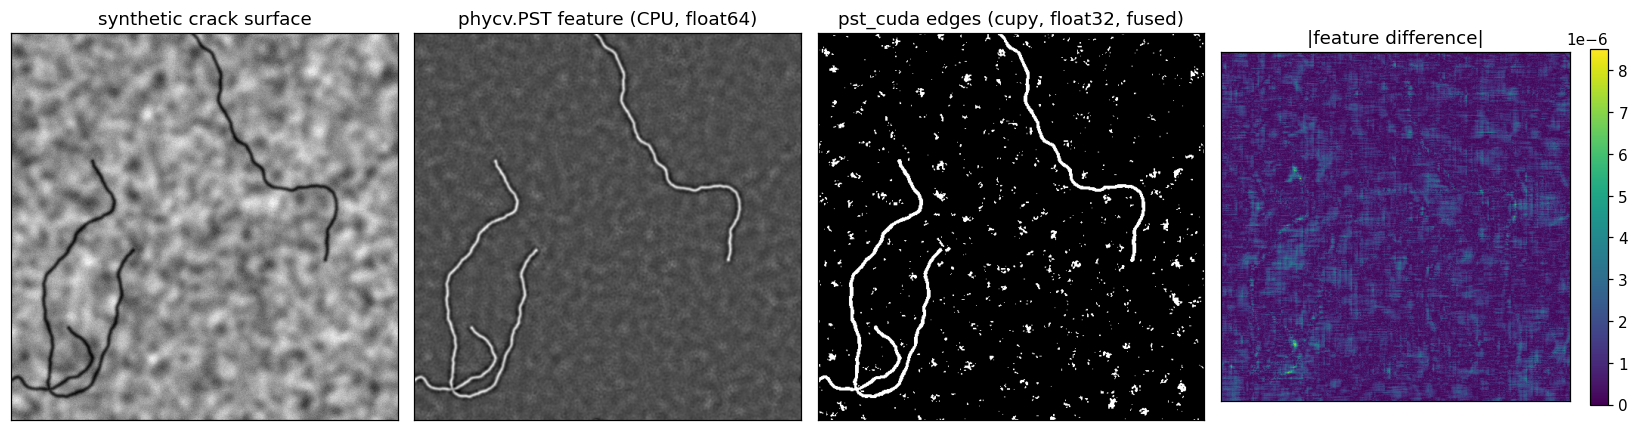

Figure 1. Left: a 512x512 synthetic concrete surface with three dark random-walk cracks. Second: the analog PST feature from phycv (bright = high phase). Third: the binary edge map from dgs.pst_cuda on the GPU; the cracks appear as outlined curves and some texture speckle survives the top-5% threshold. Right: the absolute difference between the two analog features, max 8.5e-06 (float32 rounding); 1 of 262144 edge pixels differ.


In [5]:
P = dict(S=0.4, W=20.0, sigma_LPF=0.1, thresh_min=0.0, thresh_max=0.95)
img, mask = pc.synthetic_crack_surface(512, n_cracks=3, seed=1)
ref_f, ref_o = pc.phycv_reference(img, **P)
g = pc.PSTCuda(dtype='float32', fused=True)
g.run(img, P['S'], P['W'], P['sigma_LPF'], P['thresh_min'], P['thresh_max'], True)
f, o = g.to_numpy(g.pst_feature), g.to_numpy(g.pst_output)

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('synthetic crack surface')
ax[1].imshow(ref_f, cmap='gray'); ax[1].set_title('phycv.PST feature (CPU, float64)')
ax[2].imshow(o, cmap='gray'); ax[2].set_title(f'pst_cuda edges ({BACKEND}, float32, fused)')
im = ax[3].imshow(np.abs(f - ref_f), cmap='viridis'); ax[3].set_title('|feature difference|')
plt.colorbar(im, ax=ax[3], fraction=0.046)
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.tight_layout(); plt.show()
print(f'Figure 1. Left: a 512x512 synthetic concrete surface with three dark random-walk cracks. '
      f'Second: the analog PST feature from phycv (bright = high phase). Third: the binary edge map from '
      f'dgs.pst_cuda on the GPU; the cracks appear as outlined curves and some texture speckle survives the '
      f'top-5% threshold. Right: the absolute difference between the two analog features, max {np.abs(f-ref_f).max():.1e} '
      f'(float32 rounding); {int((o != ref_o).sum())} of {o.size} edge pixels differ.')

## 4. Accuracy over many images

For each size and seed, compare against `phycv.PST`:

* **max |Δfeature|**: worst pixel of the analog feature on a 0–1 scale;
* **edge pixels differing**: binary edge-map pixels that disagree. Each one is checked to sit within $10^{-4}$ of a quantile threshold, where float32 rounding can push a tie either way.

In [6]:
rows = []
for n, seed in [(256, 0), (512, 1), (1024, 2), (2048, 3)]:
    im_, _ = pc.synthetic_crack_surface(n, n_cracks=3, seed=seed)
    rf, ro = pc.phycv_reference(im_, **P)
    sub = rf[::4, ::4]
    q = np.array([np.quantile(sub, P['thresh_max']), np.quantile(sub, P['thresh_min'])])
    configs = [('float32', False), ('float32', True), ('float64', True)]
    for dtype, fused in configs:
        p = pc.PSTCuda(dtype=dtype, fused=fused)
        p.run(im_, P['S'], P['W'], P['sigma_LPF'], P['thresh_min'], P['thresh_max'], True)
        ff, oo = p.to_numpy(p.pst_feature), p.to_numpy(p.pst_output)
        bad = oo != ro
        on_thr = bool(np.all(np.abs(rf[bad][:, None] - q[None]).min(1) < 1e-4)) if bad.any() else True
        rows.append(dict(size=f'{n}²', backend=BACKEND, dtype=dtype, fused=fused,
                         max_feature_diff=float(np.abs(ff - rf).max()),
                         edge_pixels_differing=int(bad.sum()), pixels=bad.size,
                         all_mismatches_on_threshold=on_thr))
acc = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:.2e}'.format)
display(acc)
print('worst float32 feature difference:', f"{acc[acc.dtype=='float32'].max_feature_diff.max():.2e}")
print('worst float64 feature difference:', f"{acc[acc.dtype=='float64'].max_feature_diff.max():.2e}")

,size,backend,dtype,fused,max_feature_diff,edge_pixels_differing,pixels,all_mismatches_on_threshold
0,256²,cupy,float32,False,1.55e-05,0,65536,True
1,256²,cupy,float32,True,8.73e-06,0,65536,True
2,256²,cupy,float64,True,2.76e-14,0,65536,True
3,512²,cupy,float32,False,2.66e-05,2,262144,True
4,512²,cupy,float32,True,8.52e-06,1,262144,True
5,512²,cupy,float64,True,2.65e-14,0,262144,True
6,1024²,cupy,float32,False,2.09e-05,4,1048576,True
7,1024²,cupy,float32,True,1.06e-05,2,1048576,True
8,1024²,cupy,float64,True,3.69e-14,0,1048576,True
9,2048²,cupy,float32,False,1.67e-05,35,4194304,True


worst float32 feature difference: 2.66e-05
worst float64 feature difference: 3.69e-14


## 5. Benchmark: CPU vs GPU, 256² to 4096²

Each method processes one frame with its kernels already built and the image already loaded (the steady state of a video stream). Best of $N$ runs:

* CPU methods: `time.perf_counter`;
* GPU device time: CUDA events (`cupy.cuda.Event`) around `apply_kernel`;
* GPU "with host copies": `perf_counter` + `deviceSynchronize`, including upload of the image and download of the edge map;
* `phycv.PST_GPU` (PyTorch): `perf_counter` + `torch.cuda.synchronize`, image already on the GPU.

The full morphological step (quantiles + threshold) is included for every method.

In [7]:
bench = pc.benchmark(sizes=(256, 512, 1024, 2048, 4096), repeats=7)
px = np.array(bench['pixels'], float)
methods = [k for k in bench if k not in ('sizes', 'pixels')]
times = pd.DataFrame({m: np.array(bench[m]) * 1e3 for m in methods}, index=[f'{s}²' for s in bench['sizes']]).T
pd.set_option('display.float_format', '{:.3f}'.format)
print('best-of-N time per frame (ms):')
display(times)

best-of-N time per frame (ms):


,256²,512²,1024²,2048²,4096²
"phycv PST (NumPy, CPU f64)",7.680,48.375,166.547,862.997,3480.556
"pst_cuda NumPy fallback (CPU f32, fused)",2.834,16.671,79.716,393.374,1684.001
"pst_cuda CuPy (4-FFT, device)",1.062,1.269,7.496,8.466,34.029
"pst_cuda CuPy (4-FFT, with host copies)",1.307,2.248,5.125,17.790,69.805
"pst_cuda CuPy (fused 2-FFT, device)",1.171,2.675,1.549,5.857,26.235
"pst_cuda CuPy (fused 2-FFT, with host copies)",1.328,2.631,4.050,14.915,63.338
"phycv PST_GPU (PyTorch, device)",2.237,2.532,2.491,8.866,47.740


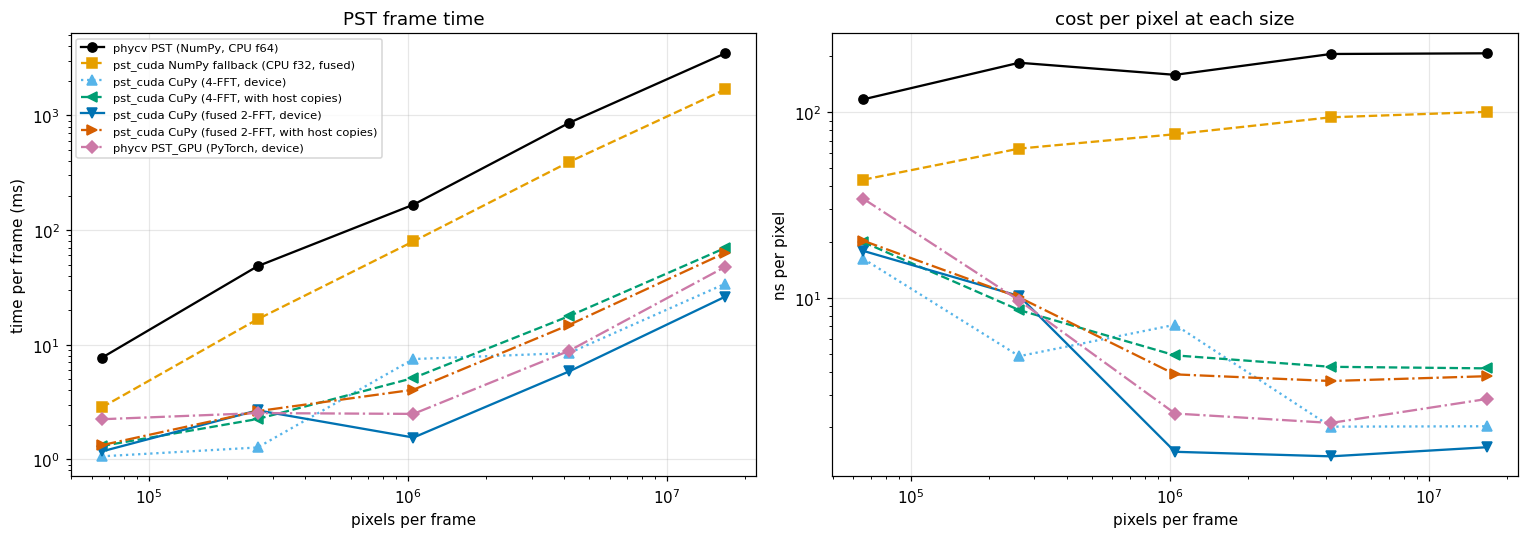

Figure 2. Left: best-of-N time for one PST frame versus pixel count on log-log axes, one curve per method (colour and line style both distinguish them). The CPU curves rise roughly in proportion to pixel count across the whole range; the GPU curves are flat near 1.2 ms up to about 1024² (fixed launch and synchronisation overhead), then rise. Right: the same data as time per pixel. GPU cost per pixel falls with size until the overhead is amortised; at 4096² phycv CPU spends 207 ns/pixel and the fused CuPy path 1.56 ns/pixel.


In [8]:
style = {
 'phycv PST (NumPy, CPU f64)':                   (OI['black'],  '-',  'o'),
 'pst_cuda NumPy fallback (CPU f32, fused)':     (OI['orange'], '--', 's'),
 'phycv PST_GPU (PyTorch, device)':              (OI['purple'], '-.', 'D'),
 'pst_cuda CuPy (4-FFT, device)':                (OI['sky'],    ':',  '^'),
 'pst_cuda CuPy (fused 2-FFT, device)':          (OI['blue'],   '-',  'v'),
 'pst_cuda CuPy (4-FFT, with host copies)':      (OI['green'],  '--', '<'),
 'pst_cuda CuPy (fused 2-FFT, with host copies)':(OI['red'],    '-.', '>'),
}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for m in methods:
    c, ls, mk = style.get(m, (OI['yellow'], '-', 'x'))
    t = np.array(bench[m])
    ax[0].loglog(px, t * 1e3, ls=ls, marker=mk, color=c, label=m)
    ax[1].semilogx(px, t / px * 1e9, ls=ls, marker=mk, color=c, label=m)
ax[0].set_xlabel('pixels per frame'); ax[0].set_ylabel('time per frame (ms)'); ax[0].set_title('PST frame time')
ax[1].set_xlabel('pixels per frame'); ax[1].set_ylabel('ns per pixel'); ax[1].set_yscale('log'); ax[1].set_title('cost per pixel at each size')
ax[0].legend(fontsize=7.5)
plt.tight_layout(); plt.show()
t_cpu = np.array(bench['phycv PST (NumPy, CPU f64)'])
t_gpu = np.array(bench.get('pst_cuda CuPy (fused 2-FFT, device)', [np.nan]*len(px)))
print(f'Figure 2. Left: best-of-N time for one PST frame versus pixel count on log-log axes, one curve per method '
      f'(colour and line style both distinguish them). The CPU curves rise roughly in proportion to pixel count across the whole range; '
      f'the GPU curves are flat near {t_gpu[0]*1e3:.1f} ms up to about 1024² (fixed launch and synchronisation overhead), then rise. '
      f'Right: the same data as time per pixel. GPU cost per pixel falls with size until the overhead is amortised; '
      f'at 4096² phycv CPU spends {t_cpu[-1]/px[-1]*1e9:.0f} ns/pixel and the fused CuPy path {t_gpu[-1]/px[-1]*1e9:.2f} ns/pixel.')

### 5.1 Least-squares fit: time = overhead + slope × pixels

Same method as `regress_line` in `dgs/rigid_body_harsh.py` (`np.polyfit` degree 1, $r^2$ from residual variance). FFTs cost $\propto N\log N$, not $N$, so a straight line is an approximation. A *negative* overhead is the sign of that curvature: the line is pulled down by the large sizes and is not a real negative cost.

In [9]:
fit = []
for m in methods:
    ov, ns, r2 = pc.fit_ns_per_pixel(px, bench[m])
    fit.append(dict(method=m, overhead_ms=ov * 1e3, ns_per_pixel=ns, r2=r2,
                    frame_4096_ms=bench[m][-1] * 1e3, fps_4096=1 / bench[m][-1]))
fit = pd.DataFrame(fit).set_index('method')
pd.set_option('display.float_format', '{:.3f}'.format)
display(fit)

base = np.array(bench['phycv PST (NumPy, CPU f64)'])
sp_rows = {m: base / np.array(bench[m]) for m in methods if m != 'phycv PST (NumPy, CPU f64)'}
speed = pd.DataFrame(sp_rows, index=[f'{s}²' for s in bench['sizes']]).T
pd.set_option('display.float_format', '{:.1f}'.format)
print('speedup over phycv.PST (CPU), measured:')
display(speed)
if 'phycv PST_GPU (PyTorch, device)' in bench and 'pst_cuda CuPy (fused 2-FFT, device)' in bench:
    r = np.array(bench['phycv PST_GPU (PyTorch, device)']) / np.array(bench['pst_cuda CuPy (fused 2-FFT, device)'])
    print('fused CuPy vs phycv PST_GPU (PyTorch), ratio of times per size:', np.round(r, 2))

,overhead_ms,ns_per_pixel,r2,frame_4096_ms,fps_4096
method,,,,,
"phycv PST (NumPy, CPU f64)",-19.091,208.594,1.000,3480.556,0.287
"pst_cuda NumPy fallback (CPU f32, fused)",-16.700,101.133,1.000,1684.001,0.594
"pst_cuda CuPy (4-FFT, device)",1.969,1.901,0.977,34.029,29.387
"pst_cuda CuPy (4-FFT, with host copies)",0.929,4.100,1.000,69.805,14.326
"pst_cuda CuPy (fused 2-FFT, device)",0.815,1.495,0.990,26.235,38.117
"pst_cuda CuPy (fused 2-FFT, with host copies)",0.640,3.717,0.999,63.338,15.788
"phycv PST_GPU (PyTorch, device)",0.368,2.776,0.990,47.740,20.947


speedup over phycv.PST (CPU), measured:


,256²,512²,1024²,2048²,4096²
"pst_cuda NumPy fallback (CPU f32, fused)",2.7,2.9,2.1,2.2,2.1
"pst_cuda CuPy (4-FFT, device)",7.2,38.1,22.2,101.9,102.3
"pst_cuda CuPy (4-FFT, with host copies)",5.9,21.5,32.5,48.5,49.9
"pst_cuda CuPy (fused 2-FFT, device)",6.6,18.1,107.5,147.3,132.7
"pst_cuda CuPy (fused 2-FFT, with host copies)",5.8,18.4,41.1,57.9,55.0
"phycv PST_GPU (PyTorch, device)",3.4,19.1,66.9,97.3,72.9


fused CuPy vs phycv PST_GPU (PyTorch), ratio of times per size: [1.91 0.95 1.61 1.51 1.82]


## 6. Reading the results

* **Accuracy.** In float32 the GPU feature matches phycv's float64 feature to about $10^{-5}$ on a 0–1 scale, and the binary edge map differs only at pixels sitting on a quantile threshold. In float64 the match is at round-off level, for both the literal 4-FFT sequence and the fused 2-FFT one, so the fusion is exact.
* **Speed.** The tables above are the measurement. Small frames are limited by a roughly fixed ~1 ms per-frame overhead on the GPU (many small kernel launches plus the quantile sort and the min/max reductions that synchronise). Large frames are limited by FFT memory traffic, and there the fused path, with half the FFTs, is the fastest GPU variant.
* **Host copies matter.** Including image upload and edge-map download roughly doubles the GPU time at 4096². A real camera pipeline should keep frames on the GPU (pinned memory, CUDA streams) or download only the result it needs.
* **PyTorch vs CuPy.** The comparison is mixed, so read the ratio printed above rather than a headline. phycv's own `PST_GPU` can match or beat the CuPy path in the 512²–1024² range, where both are near their overhead floor and run-to-run noise is a sizeable fraction of the ~1–3 ms. At 2048² and 4096² the fused CuPy path has been consistently faster in these runs, from removing two FFTs and caching the low-pass filter.

**Limitations.**
- One machine (RTX 4060 laptop GPU, one CPU); numbers move with clocks, thermals and background load.
- Best-of-N timing reports the optimistic steady state, not the mean or the tail latency.
- Kernel build time (`init_kernel`) is excluded for every method.
- The NumPy fallback is float32 and fused, so it is not the same arithmetic as phycv's CPU path. Its speedup mixes precision and algorithm.
- The crack images are synthetic. Edge quality on real concrete photographs was not tested here.
- `load_img` converts RGB with BT.601 weights in RGB order. phycv uses OpenCV's BGR order, so feed grayscale images when comparing.

**References** (written from memory; verify before citing)

[1] M. H. Asghari and B. Jalali, "Edge detection in digital images using dispersive phase stretch transform," *Int. J. Biomed. Imaging*, vol. 2015, Art. no. 687819, 2015.

[2] Y. Zhou, C. MacPhee, M. Suthar, and B. Jalali, "PhyCV: The first physics-inspired computer vision library," *arXiv:2301.12531*, 2023.

[3] R. Okuta, Y. Unno, D. Nishino, S. Hido, and C. Loomis, "CuPy: A NumPy-compatible library for NVIDIA GPU calculations," in *Proc. Workshop on Machine Learning Systems (LearningSys), NeurIPS*, 2017.

[4] K. Goda and B. Jalali, "Dispersive Fourier transformation for fast continuous single-shot measurements," *Nature Photon.*, vol. 7, no. 2, pp. 102–112, 2013.

[5] J. W. Cooley and J. W. Tukey, "An algorithm for the machine calculation of complex Fourier series," *Math. Comput.*, vol. 19, no. 90, pp. 297–301, 1965.